# 2. Segmentation Baseline

We apply a pretrained Omnipose model to D1 images and compare its
predicted cell masks with the ground-truth segmentation masks.
This establishes a baseline before any fine-tuning.

## 2.1 Environment Check

We record the Python version and system architecture before installing
Omnipose to identify compatibility requirements.


In [1]:
import sys
import platform

print(f"Python version: {sys.version}")
print(f"Python executable: {sys.executable}")
print(f"Operating system: {platform.system()}")
print(f"Architecture: {platform.machine()}")

Python version: 3.10.22 (main, Oct 29 2026, 20:29:19) [Clang 20.1.8 ]
Python executable: /opt/anaconda3/envs/blt-clean/bin/python
Operating system: Darwin
Architecture: arm64


In [2]:
import sys
from cellpose_omni import models

print(f"Python executable: {sys.executable}")
print("Omnipose is ready.")

/opt/anaconda3/envs/blt-clean/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python executable: /opt/anaconda3/envs/blt-clean/bin/python
Omnipose is ready.


## 2.2 Installing Omnipose

We install Omnipose in the notebook's active Python environment.
The initial segmentation baseline will use CPU execution.

In [3]:
%pip install omnipose

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install "ncolor==1.5.3"

Note: you may need to restart the kernel to use updated packages.


In [5]:
from importlib.metadata import version
from ncolor import unique_nonzero
from cellpose_omni import models
import torch

print(f"ncolor version: {version('ncolor')}")
print(f"Omnipose version: {version('omnipose')}")
print(f"PyTorch version: {torch.__version__}")
print("Omnipose imported successfully.")

ncolor version: 1.5.3
Omnipose version: 1.1.4
PyTorch version: 2.14.1
Omnipose imported successfully.


## 2.3 Running the Pretrained Segmentation Baseline

We apply the pretrained `bact_phase_omni` model to frame 0 of
sequence 00 using CPU execution. Ground-truth masks are loaded
only for comparison and are not provided to the model.

In [6]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from cellpose_omni import models

data_dir = Path("../data/ctc_format")

image = tifffile.imread(data_dir / "00/t0000.tif")
ground_truth = tifffile.imread(
    data_dir / "00_GT/SEG/man_seg0000.tif"
)

# Load pretrained weights. The first run may download the model.
model = models.CellposeModel(
    gpu=False,
    model_type="bact_phase_omni",
)

start = time.perf_counter()

masks, flows, styles = model.eval(
    [image],
    channels=[0, 0],
    diameter=None,
    omni=True,
)

predicted_mask = masks[0]
elapsed = time.perf_counter() - start

print(f"Segmentation time: {elapsed:.2f} seconds")
print(f"Ground-truth cells: {np.count_nonzero(np.unique(ground_truth))}")
print(f"Predicted cells: {np.count_nonzero(np.unique(predicted_mask))}")

2026-11-21 17:55:05,768	[INFO]     cellpose_omni/models.py       __init__....()	 line 440	>>bact_phase_omni<< model set to be used
2026-11-21 17:55:05,769	[INFO]                                   cach..._path()	 line  64	Downloading: "https://raw.githubusercontent.com/kevinjohncutler/omnipose-models/main/bact_phase_omnitorch_0" to /Users/ayca.aydogdu/.cellpose/models/bact_phase_omnitorch_0

https://raw.githubusercontent.com/kevinjohncutler/omnipose-models/main/bact_phase_omnitorch_0 /Users/ayca.aydogdu/.cellpose/models/bact_phase_omnitorch_0


100%|██████████| 25.3M/25.3M [00:02<00:00, 11.1MB/s]


2026-11-21 17:55:09,662	[INFO]     cellpose_omni/core.py         assi...evice()	 line 118	Using CPU.
2026-11-21 17:55:09,693	[INFO]                                   __init__....()	 line 218	u-net config: ([2, 32, 64, 128, 256], 4, 2)
Segmentation time: 5.64 seconds
Ground-truth cells: 2
Predicted cells: 10


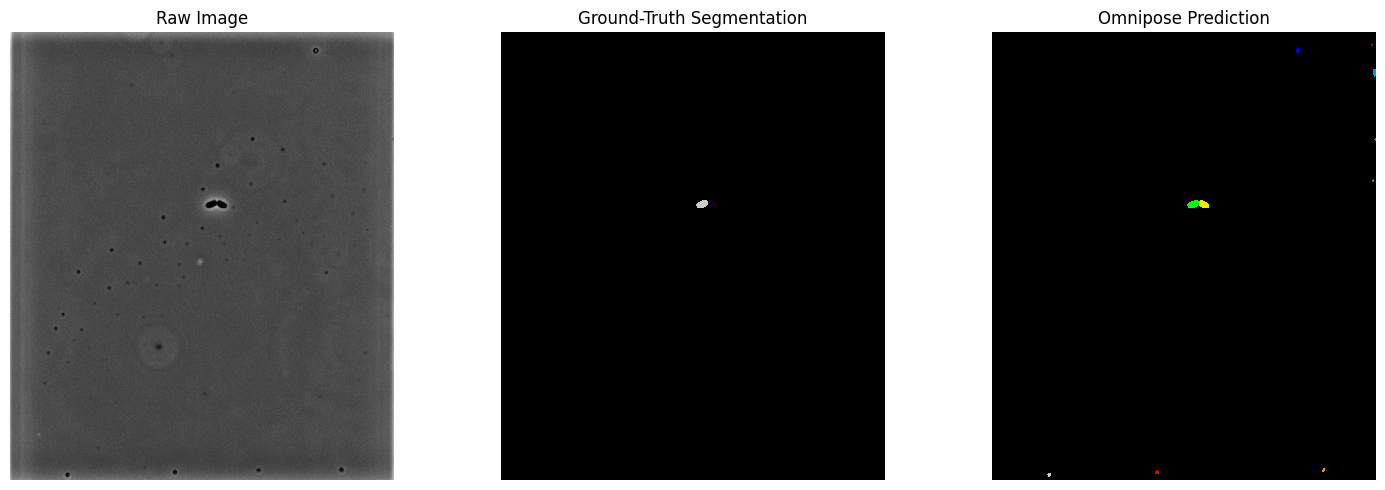

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

panels = [
    (image, "Raw Image", "gray"),
    (ground_truth, "Ground-Truth Segmentation", "nipy_spectral"),
    (predicted_mask, "Omnipose Prediction", "nipy_spectral"),
]

for ax, (array, title, cmap) in zip(axes, panels):
    ax.imshow(array, cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.4 Visual Inspection of the Prediction

The prediction contains masks near the two annotated cells and
additional small detections near the image boundaries. We inspect
a crop around the annotated cells before quantitative evaluation.
Cropping is used only for visualization.

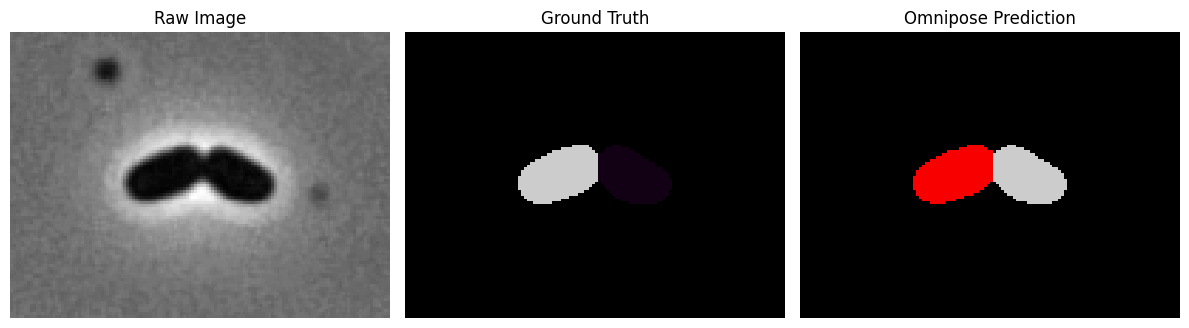

In [8]:
# Find a visualization crop around the annotated cells.
rows, cols = np.where(ground_truth > 0)
padding = 40

y_min = max(0, rows.min() - padding)
y_max = min(image.shape[0], rows.max() + padding + 1)
x_min = max(0, cols.min() - padding)
x_max = min(image.shape[1], cols.max() + padding + 1)

crop = np.s_[y_min:y_max, x_min:x_max]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

panels = [
    (image[crop], "Raw Image", "gray"),
    (ground_truth[crop], "Ground Truth", "nipy_spectral"),
    (predicted_mask[crop], "Omnipose Prediction", "nipy_spectral"),
]

for ax, (array, title, cmap) in zip(axes, panels):
    ax.imshow(array, cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.5 Quantitative Segmentation Evaluation

We match predicted and reference cells one-to-one at IoU ≥ 0.5.
We report true positives, false positives, false negatives,
precision, recall, and F1 on the full frame, including boundary
detections. This single-frame result is an initial sanity check.

In [9]:
from scipy.optimize import linear_sum_assignment

gt_ids = np.unique(ground_truth)
gt_ids = gt_ids[gt_ids != 0]

pred_ids = np.unique(predicted_mask)
pred_ids = pred_ids[pred_ids != 0]

# Compute pairwise intersection-over-union.
iou = np.zeros((len(gt_ids), len(pred_ids)))

for i, gt_id in enumerate(gt_ids):
    gt_cell = ground_truth == gt_id

    for j, pred_id in enumerate(pred_ids):
        pred_cell = predicted_mask == pred_id
        intersection = np.count_nonzero(gt_cell & pred_cell)
        union = np.count_nonzero(gt_cell | pred_cell)
        iou[i, j] = intersection / union

threshold = 0.5

if iou.size:
    # Prioritize the number of valid matches, then their IoU.
    bonus = min(iou.shape) + 1
    scores = (iou >= threshold) * bonus + iou
    gt_indices, pred_indices = linear_sum_assignment(-scores)
    tp = int(np.sum(iou[gt_indices, pred_indices] >= threshold))
else:
    tp = 0

fp = len(pred_ids) - tp
fn = len(gt_ids) - tp

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

print(f"True positives: {tp}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1: {f1:.3f}")

True positives: 2
False positives: 8
False negatives: 0
Precision: 0.200
Recall: 1.000
F1: 0.333


### Initial Result

On sequence 00, frame 0, the pretrained model detected both annotated
cells at IoU ≥ 0.5 but also produced eight unmatched predictions.
Precision was 0.200, recall was 1.000, and F1 was 0.333.

This single-frame result suggests that false-positive detections require
further investigation. It does not establish dataset-level performance.

## 2.6 Inspecting False Positives

We inspect the area and location of each predicted object.
Predictions are classified using the existing one-to-one matching
at IoU ≥ 0.5. No filtering is applied.

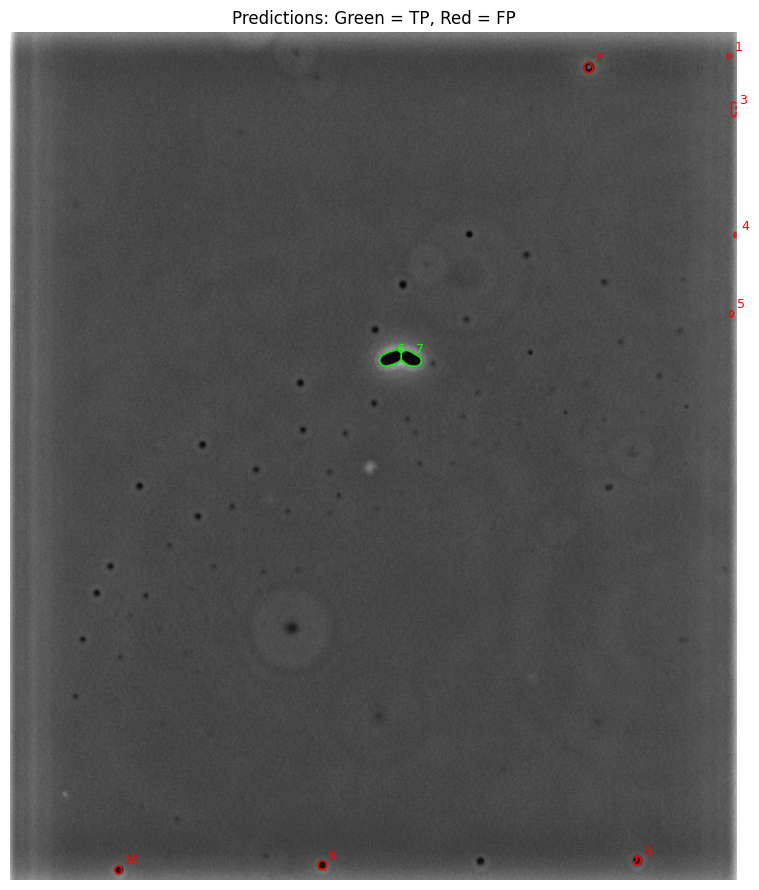

,prediction_id,status,area_pixels,center_x,center_y,touches_border
3,4,FP,21,936.0,261.2,True
0,1,FP,28,927.4,30.7,False
4,5,FP,32,930.8,362.8,False
7,8,FP,61,809.6,1068.9,False
9,10,FP,69,139.2,1080.5,False
8,9,FP,90,402.6,1074.3,False
1,2,FP,109,746.2,45.2,False
2,3,FP,111,933.8,98.6,True
6,7,TP,390,516.7,420.7,False
5,6,TP,430,491.1,420.2,False


In [10]:
import pandas as pd

# Recover predictions accepted by the previous matching step.
matched_pred_ids = set()

if iou.size:
    for i, j in zip(gt_indices, pred_indices):
        if iou[i, j] >= threshold:
            matched_pred_ids.add(int(pred_ids[j]))

records = []
height, width = predicted_mask.shape

fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(image, cmap="gray")

for pred_id in pred_ids:
    mask = predicted_mask == pred_id
    rows, cols = np.where(mask)

    is_matched = int(pred_id) in matched_pred_ids
    color = "lime" if is_matched else "red"

    touches_border = bool(
        (rows == 0).any() or (rows == height - 1).any()
        or (cols == 0).any() or (cols == width - 1).any()
    )

    records.append({
        "prediction_id": int(pred_id),
        "status": "TP" if is_matched else "FP",
        "area_pixels": int(mask.sum()),
        "center_x": round(cols.mean(), 1),
        "center_y": round(rows.mean(), 1),
        "touches_border": touches_border,
    })

    ax.contour(mask, levels=[0.5], colors=[color], linewidths=1)
    ax.annotate(
        str(pred_id),
        (cols.mean(), rows.mean()),
        xytext=(4, 4),
        textcoords="offset points",
        color=color,
        fontsize=9,
    )

ax.set_title("Predictions: Green = TP, Red = FP")
ax.axis("off")
plt.tight_layout()
plt.show()

prediction_summary = pd.DataFrame(records)
display(prediction_summary.sort_values(["status", "area_pixels"]))